# Pixel-art experiments

Compare a handful of ways to turn a photo into pixel art. Run the setup and preview cells to see the results; **nothing is saved unless you run the final save cell**.

Run the setup cell and choose a folder; the notebook finds supported image files and loads the selected one. **Nothing is saved unless you run the final save cell.**

Set `IMAGE_INDEX` in the setup cell to choose another discovered image, and adjust `PIXEL_SIZE` or `COLOR_COUNT` to experiment.

Found 1 image(s) in D:\hocj\Digital_Image_Processing\Project\img:
  0: Screenshot 2026-09-18 162621.png

Selected Screenshot 2026-09-18 162621.png (344 x 459)


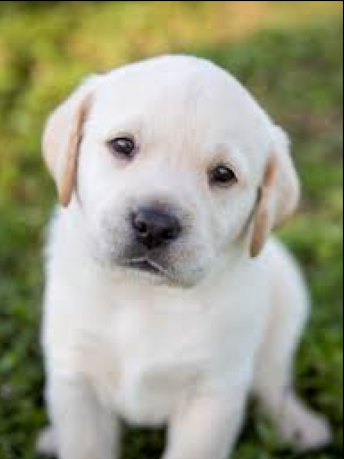

In [13]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageOps

# Leave empty to open a folder picker, or enter a folder path directly.
IMAGE_FOLDER = r"D:\hocj\Digital_Image_Processing\Project\img"
# Index in the discovered image list (starts at 0).
IMAGE_INDEX = 0

# Larger blocks create chunkier pixels. COLOR_COUNT applies to palette quantization.
PIXEL_SIZE = 3
COLOR_COUNT = 32

if not IMAGE_FOLDER.strip():
    import tkinter as tk
    from tkinter import filedialog

    picker = tk.Tk()
    picker.withdraw()
    try:
        IMAGE_FOLDER = filedialog.askdirectory(title="Choose a folder containing images")
    finally:
        picker.destroy()

if not IMAGE_FOLDER:
    raise RuntimeError("No folder selected. Run this cell again and choose an image folder.")

folder_path = Path(IMAGE_FOLDER).expanduser()
if not folder_path.is_dir():
    raise NotADirectoryError(f"Image folder not found: {folder_path}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
image_files = sorted(
    (path for path in folder_path.iterdir() if path.is_file() and path.suffix.lower() in image_extensions),
    key=lambda path: path.name.casefold(),
)
if not image_files:
    raise FileNotFoundError(f"No supported images found directly inside {folder_path}")

print(f"Found {len(image_files)} image(s) in {folder_path}:")
for index, path in enumerate(image_files):
    print(f"  {index}: {path.name}")

if not 0 <= IMAGE_INDEX < len(image_files):
    raise IndexError(f"IMAGE_INDEX must be from 0 to {len(image_files) - 1}")

image_path = image_files[IMAGE_INDEX]
with Image.open(image_path) as source:
    original = ImageOps.exif_transpose(source).convert("RGB")
print(f"\nSelected {image_path.name} ({original.width} x {original.height})")
display(original)

## Methods

- **Nearest neighbor:** shrink and enlarge with hard-edged sampling.
- **Box average:** average each block before enlarging, for smoother color transitions.
- **Adaptive palette / K-means:** reduce the pixel grid to a limited number of colors using two different palette strategies.
- **Ordered / Floyd–Steinberg / Atkinson dithering:** reduce each channel to a few levels and use patterns or diffused error to simulate extra shades.
- **Edge outline:** emphasize strong edges on top of the pixelated palette image for a sprite-like look.

Dithering and color clustering run on the small image before enlarging, so their patterns align with the pixel grid.

In [14]:
def downsample_size(image, pixel_size):
    if pixel_size < 1:
        raise ValueError("PIXEL_SIZE must be at least 1")
    return max(1, image.width // pixel_size), max(1, image.height // pixel_size)


def enlarge_nearest(small, original_size):
    return small.resize(original_size, Image.Resampling.NEAREST)


def pixelate_nearest(image, pixel_size):
    small = image.resize(downsample_size(image, pixel_size), Image.Resampling.NEAREST)
    return enlarge_nearest(small, image.size)


def pixelate_box(image, pixel_size):
    small = image.resize(downsample_size(image, pixel_size), Image.Resampling.BOX)
    return enlarge_nearest(small, image.size)


def pixelate_palette(image, pixel_size, color_count):
    if not 2 <= color_count <= 256:
        raise ValueError("COLOR_COUNT must be between 2 and 256")
    small = image.resize(downsample_size(image, pixel_size), Image.Resampling.BOX)
    quantized = small.quantize(
        colors=color_count,
        method=Image.Quantize.MEDIANCUT,
        dither=Image.Dither.NONE,
    ).convert("RGB")
    return enlarge_nearest(quantized, image.size)


def bayer_matrix(order=4):
    if order not in (2, 4, 8):
        raise ValueError("Bayer matrix order must be 2, 4, or 8")
    matrix = np.array([[0, 2], [3, 1]], dtype=np.float32)
    while matrix.shape[0] < order:
        n = matrix.shape[0]
        matrix = np.block(
            [[4 * matrix, 4 * matrix + 2], [4 * matrix + 3, 4 * matrix + 1]]
        )
    return matrix


def quantize_ordered(image, levels=4, order=4):
    if levels < 2:
        raise ValueError("levels must be at least 2")
    values = np.asarray(image, dtype=np.float32)
    thresholds = (bayer_matrix(order) + 0.5) / (order * order)
    thresholds = np.tile(thresholds, (int(np.ceil(values.shape[0] / order)), int(np.ceil(values.shape[1] / order))))
    thresholds = thresholds[: values.shape[0], : values.shape[1], None]
    scaled = values / 255.0 * (levels - 1)
    lower = np.floor(scaled)
    indices = lower + ((scaled - lower) > thresholds)
    result = np.clip(indices, 0, levels - 1) * (255.0 / (levels - 1))
    return Image.fromarray(np.rint(result).astype(np.uint8), mode="RGB")


def quantize_floyd_steinberg(image, levels=4):
    if levels < 2:
        raise ValueError("levels must be at least 2")
    work = np.asarray(image, dtype=np.float32).copy()
    height, width, _ = work.shape
    step = 255.0 / (levels - 1)
    for y in range(height):
        for x in range(width):
            old = np.clip(work[y, x], 0, 255)
            new = np.rint(old / step) * step
            work[y, x] = new
            error = old - new
            if x + 1 < width:
                work[y, x + 1] += error * (7 / 16)
            if y + 1 < height:
                if x > 0:
                    work[y + 1, x - 1] += error * (3 / 16)
                work[y + 1, x] += error * (5 / 16)
                if x + 1 < width:
                    work[y + 1, x + 1] += error * (1 / 16)
    result = np.clip(np.rint(work), 0, 255).astype(np.uint8)
    return Image.fromarray(result, mode="RGB")


def quantize_atkinson(image, levels=4):
    if levels < 2:
        raise ValueError("levels must be at least 2")
    work = np.asarray(image, dtype=np.float32).copy()
    height, width, _ = work.shape
    step = 255.0 / (levels - 1)
    for y in range(height):
        for x in range(width):
            old = np.clip(work[y, x], 0, 255)
            new = np.rint(old / step) * step
            work[y, x] = new
            error = (old - new) / 8
            for dx, dy in ((1, 0), (2, 0), (-1, 1), (0, 1), (1, 1), (0, 2)):
                nx, ny = x + dx, y + dy
                if 0 <= nx < width and ny < height:
                    work[ny, nx] += error
    result = np.clip(np.rint(work), 0, 255).astype(np.uint8)
    return Image.fromarray(result, mode="RGB")


def pixelate_kmeans(image, pixel_size, color_count, max_iterations=20):
    if not 2 <= color_count <= 256:
        raise ValueError("COLOR_COUNT must be between 2 and 256")
    small = image.resize(downsample_size(image, pixel_size), Image.Resampling.BOX)
    pixels = np.asarray(small, dtype=np.float32).reshape(-1, 3)
    cluster_count = min(color_count, len(pixels))
    rng = np.random.default_rng(0)
    centers = pixels[rng.choice(len(pixels), size=cluster_count, replace=False)].copy()

    for _ in range(max_iterations):
        distances = ((pixels[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = distances.argmin(axis=1)
        counts = np.bincount(labels, minlength=cluster_count)
        new_centers = centers.copy()
        for index in range(cluster_count):
            if counts[index]:
                new_centers[index] = pixels[labels == index].mean(axis=0)
            else:
                new_centers[index] = pixels[distances.min(axis=1).argmax()]
        if np.allclose(new_centers, centers):
            centers = new_centers
            break
        centers = new_centers

    distances = ((pixels[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    quantized = centers[distances.argmin(axis=1)].reshape(np.asarray(small).shape)
    small_result = Image.fromarray(np.clip(np.rint(quantized), 0, 255).astype(np.uint8), mode="RGB")
    return enlarge_nearest(small_result, image.size)


def pixelate_outline(image, pixel_size, color_count, threshold=48):
    base = pixelate_palette(image, pixel_size, color_count)
    small = image.resize(downsample_size(image, pixel_size), Image.Resampling.BOX)
    edges = small.convert("L").filter(ImageFilter.FIND_EDGES)
    edge_mask = edges.point(lambda value: 255 if value >= threshold else 0)
    edge_mask = enlarge_nearest(edge_mask, image.size)
    outlined = Image.new("RGB", image.size, (20, 20, 24))
    outlined.paste(base, mask=ImageOps.invert(edge_mask))
    return outlined


def pixelate_dither(image, pixel_size, method, levels=4):
    small = image.resize(downsample_size(image, pixel_size), Image.Resampling.BOX)
    if method == "ordered":
        dithered = quantize_ordered(small, levels=levels)
    elif method == "floyd-steinberg":
        dithered = quantize_floyd_steinberg(small, levels=levels)
    elif method == "atkinson":
        dithered = quantize_atkinson(small, levels=levels)
    else:
        raise ValueError(f"Unknown dithering method: {method}")
    return enlarge_nearest(dithered, image.size)

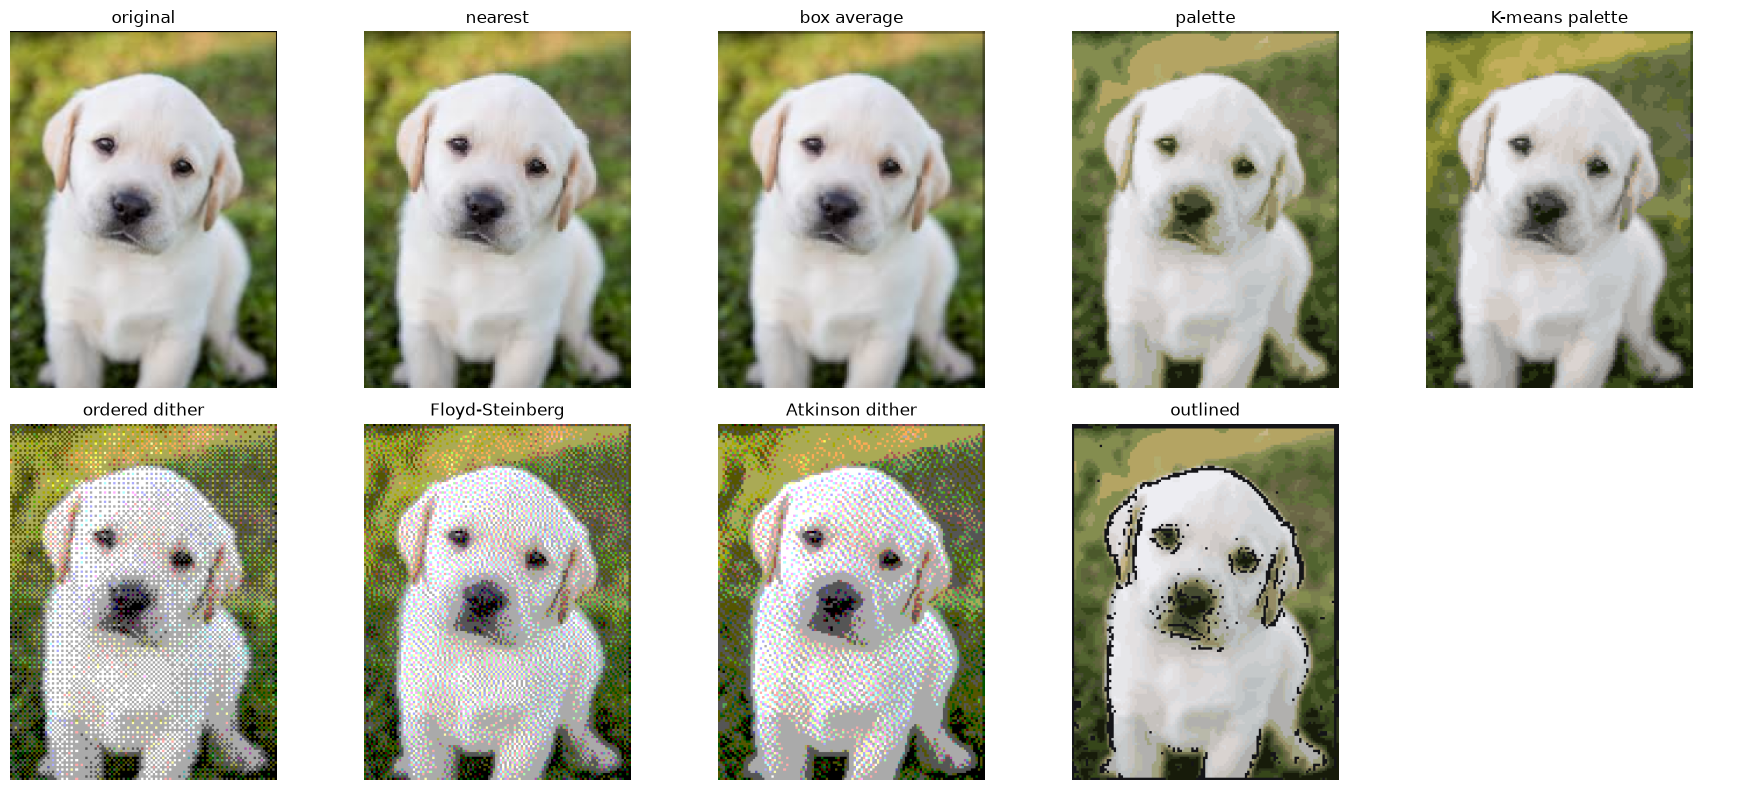

Available result names: nearest, box average, palette, K-means palette, ordered dither, Floyd-Steinberg, Atkinson dither, outlined


In [15]:
# Re-run this cell after changing PIXEL_SIZE or COLOR_COUNT to refresh all previews.
results = {
    "nearest": pixelate_nearest(original, PIXEL_SIZE),
    "box average": pixelate_box(original, PIXEL_SIZE),
    "palette": pixelate_palette(original, PIXEL_SIZE, COLOR_COUNT),
    "K-means palette": pixelate_kmeans(original, PIXEL_SIZE, COLOR_COUNT),
    "ordered dither": pixelate_dither(original, PIXEL_SIZE, "ordered"),
    "Floyd-Steinberg": pixelate_dither(original, PIXEL_SIZE, "floyd-steinberg"),
    "Atkinson dither": pixelate_dither(original, PIXEL_SIZE, "atkinson"),
    "outlined": pixelate_outline(original, PIXEL_SIZE, COLOR_COUNT),
}

previews = [("original", original), *results.items()]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, (title, result) in zip(axes.flat, previews):
    ax.imshow(result)
    ax.set_title(title)
    ax.axis("off")
for ax in axes.flat[len(previews):]:
    ax.axis("off")
fig.tight_layout()
plt.show()
print("Available result names:", ", ".join(results))

## Optional: save a result

Choose a name from `results` and an output path below, then run this cell. It saves only the selected preview; no file is written by the comparison cell.

In [16]:
SAVE_METHOD = "palette"  # Choose any name from the preview cell's results dictionary.
OUTPUT_PATH = "pixel_art.png"

if SAVE_METHOD not in results:
    raise ValueError(f"Unknown method {SAVE_METHOD!r}. Choose from: {', '.join(results)}")
output_path = Path(OUTPUT_PATH).expanduser()
results[SAVE_METHOD].save(output_path)
print(f"Saved {SAVE_METHOD!r} result to {output_path.resolve()}")

Saved 'palette' result to D:\hocj\Digital_Image_Processing\Project\pixel_art.png
